In [38]:
import numpy as np
import pandas as pd

from Tools.EDA import (plot_densites, resume_boxplot, plot_countplots,
                       heatmap_correlation_triangulaire, test_mann_whitney_multi,
                       analyse_contingence_multi)
#from FraudDetection.DataPreparation.DataCleaning import sample_data_cleaning

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import OneHotEncoder, KBinsDiscretizer

In [3]:
%load_ext autoreload
%autoreload 2

# Repertoire de travail

In [4]:
%pwd

'/home/user_daren_mabanza/data_science/projets/V2_projet_fraud_detection/02_notebooks'

In [5]:
%cd "/home/user_daren_mabanza/data_science/projets/V2_projet_fraud_detection"

/home/user_daren_mabanza/data_science/projets/V2_projet_fraud_detection


# Import des données

In [ ]:
# sample_data_cleaning()
# Modifier le fichier de config pour avec la base Sample

step_1_cleaning_data - 1. Import des données - OK
step_1_cleaning_data - 2. Traitemens spécifiques - OK
step_1_cleaning_data - 3. Suppression de colonnes - OK
step_1_cleaning_data - 4. Conversion des colonnes - OK
step_1_cleaning_data - 5. Controle minimal de la qualité des données - Nombre de colonnes : OK
step_1_cleaning_data - 5. Controle minimal de la qualité des données - 15 colonnes | is_fraud présent : OK
step_1_cleaning_data - 5. Export des données - OK


In [174]:
sample_data = pd.read_parquet("01_data/02_intermediate_data/SampleDataForEda.parquet")

In [175]:
df_copy = sample_data.copy()

In [176]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 50001 entries, 0 to 50000
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     50001 non-null  uint32        
 1   trans_date_trans_time  50001 non-null  datetime64[us]
 2   merchant               50001 non-null  category      
 3   category               50001 non-null  category      
 4   amt                    50001 non-null  float32       
 5   city                   50001 non-null  category      
 6   state                  50001 non-null  category      
 7   lat                    50001 non-null  float32       
 8   long                   50001 non-null  float32       
 9   city_pop               50001 non-null  uint32        
 10  job                    50001 non-null  category      
 11  dob                    50001 non-null  datetime64[us]
 12  merch_lat              50001 non-null  float32       
 13  merch_long  

In [48]:
df_copy.sample(7)

,id,trans_date_trans_time,merchant,category,amt,city,state,lat,long,city_pop,job,dob,merch_lat,merch_long,is_fraud
35988,35989,2019-02-25 14:06:32,"Douglas, DuBuque and McKenzie",travel,519.729980,Cokeburg,PA,40.100800,-80.065201,632,Dealer,1989-04-08,39.299412,-80.444489,0
19473,19474,2019-04-27 12:06:22,Thompson-Gleason,health_fitness,94.720001,Cardwell,MO,36.043400,-90.290703,1120,Television floor manager,1957-04-17,36.668079,-89.390984,0
12833,12834,2020-11-06 22:10:37,Kozey-Kuhlman,personal_care,2.640000,North Las Vegas,NV,36.281502,-115.148201,214518,Catering manager,1960-01-16,35.986320,-114.631401,0
44363,44364,2020-09-10 12:47:40,Mohr Inc,shopping_pos,3.120000,Shields,ND,46.183800,-101.258904,77,Film/video editor,1989-12-17,45.911800,-101.945885,0
30658,30659,2020-04-07 15:23:32,Botsford and Sons,home,35.930000,Woodville,AL,34.668900,-86.229599,3395,"Editor, commissioning",1979-01-21,34.323917,-87.020615,0
49821,49822,2019-06-05 10:00:57,Erdman-Kertzmann,gas_transport,53.150002,Des Moines,IA,41.603001,-93.633003,222785,Interior and spatial designer,1981-08-10,41.630852,-93.201836,0
30282,30283,2019-12-30 15:10:51,"Towne, Greenholt and Koepp",shopping_net,1.620000,Spring,TX,30.037701,-95.532600,316665,"Education officer, museum",1990-09-12,30.035751,-96.529404,0


In [49]:
df_copy.memory_usage()

Index                       132
id                       200004
trans_date_trans_time    400008
merchant                 117482
category                  50258
amt                      200004
city                     114295
state                     50501
lat                      200004
long                     200004
city_pop                 200004
job                      113844
dob                      400008
merch_lat                200004
merch_long               200004
is_fraud                  50001
dtype: int64

# Avant Feature Engineering

## 1. Analyse univariée

### 1.A Variables numériques

**Check de la distribution de chaque variable**

In [ ]:
colonnes_num = ["amt","city_pop"]

(<Figure size 1100x450 with 2 Axes>,
    variable      n       moyenne      mediane     ecart_type   min  \
 0       amt  50001     70.261703    47.549999     187.214493   1.0   
 1  city_pop  50001  89641.670800  2408.000000  305827.104300  23.0   
 
             max  
 0  2.711977e+04  
 1  2.906700e+06  )

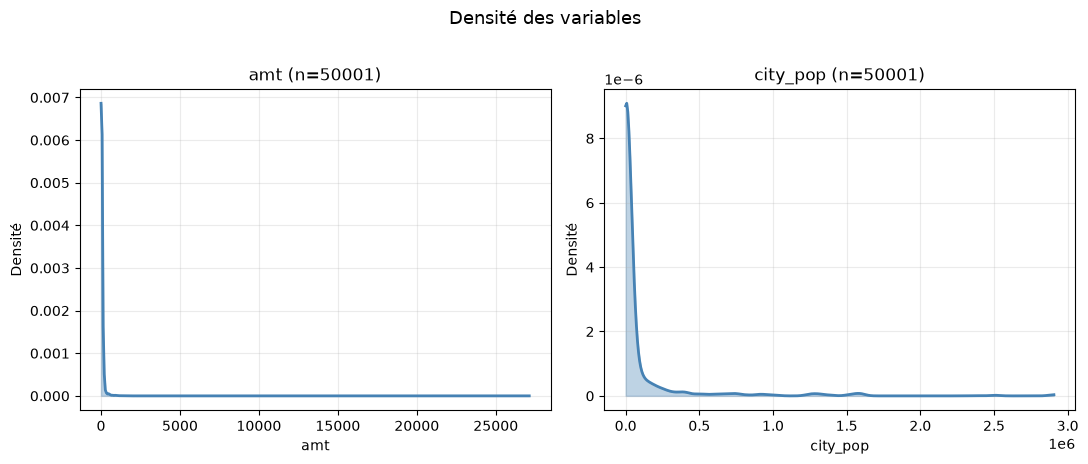

In [14]:
plot_densites(df=df_copy,
              colonnes=colonnes_num)

**Check des valeurs aberrantes pour chaque variable**

In [16]:
resume_boxplot(df=df_copy,
               colonnes=colonnes_num,
               iqr_factor=1.5)

,variable,n,borne_basse,Q1,mediane,moyenne,Q3,borne_haute,IQR,nb_outliers_bas,nb_outliers_haut
0,amt,50001,-100.559998,9.66,47.549999,70.261703,83.139999,193.360001,73.480003,0,2551
1,city_pop,50001,-27685.000000,737.00,2408.000000,89641.670800,19685.000000,48107.000000,18948.000000,0,9298


### 1.B Variables catégorielles 

In [28]:
colonnes_cat = ["merchant","category","city","state","job"]

In [30]:
df_copy[colonnes_cat].nunique()

merchant    693
category     14
city        858
state        50
job         485
dtype: int64

**Comptage des modalités pour chaque variable**

In [40]:
print(df_copy["merchant"].value_counts().nlargest(5))
print("---")
print(df_copy["category"].value_counts().nlargest(5))
print("---")
print(df_copy["city"].value_counts().nlargest(5))
print("---")
print(df_copy["state"].value_counts().nlargest(5))
print("---")
print(df_copy["job"].value_counts().nlargest(5))

merchant
Kilback LLC      175
Cormier LLC      152
Boyer PLC        149
Schumm PLC       143
Dickinson Ltd    135
Name: count, dtype: int64
---
category
gas_transport    5021
home             4799
grocery_pos      4777
shopping_pos     4458
kids_pets        4333
Name: count, dtype: int64
---
city
Birmingham     208
Utica          200
Phoenix        199
San Antonio    195
Arcadia        182
Name: count, dtype: int64
---
state
TX    3658
NY    3317
PA    3140
CA    2169
OH    1721
Name: count, dtype: int64
---
job
Film/video editor             391
Exhibition designer           342
Naval architect               331
Materials engineer            319
Designer, ceramics/pottery    314
Name: count, dtype: int64


(<Figure size 1100x450 with 2 Axes>,
    variable      n  nb_categories  nb_manquants categorie_dominante  \
 0  category  50001             14             0       gas_transport   
 1     state  50001             50             0                  TX   
 
    freq_dominante  
 0          0.1004  
 1          0.0732  )

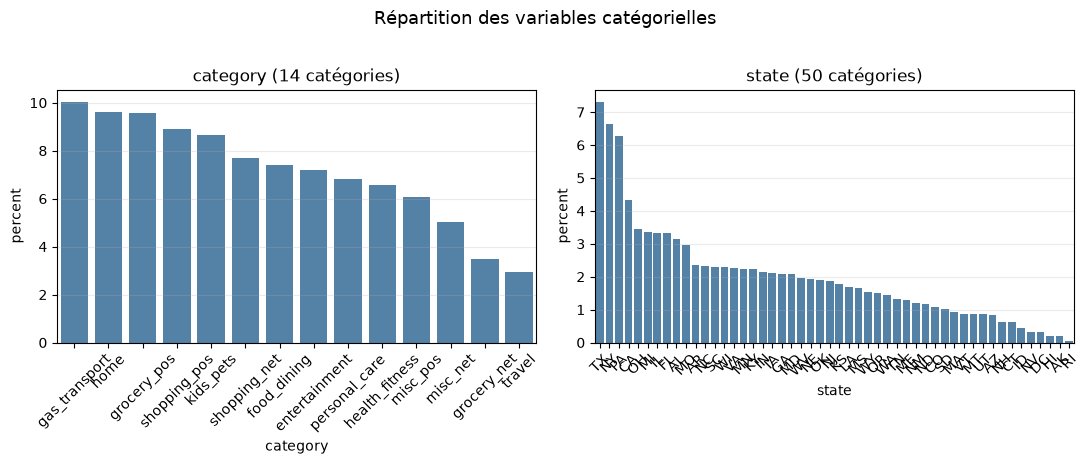

In [38]:
plot_countplots(df=df_copy,
                colonnes=["category","state"],
                order_by_freq=True,
                stat="percent")

## 2. Analyse bivariée

### 2.A Numériques | Numériques

**Heatmap des corrélations (Pearson)**

/tmp/ipykernel_33186/2222175995.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_corr.show()


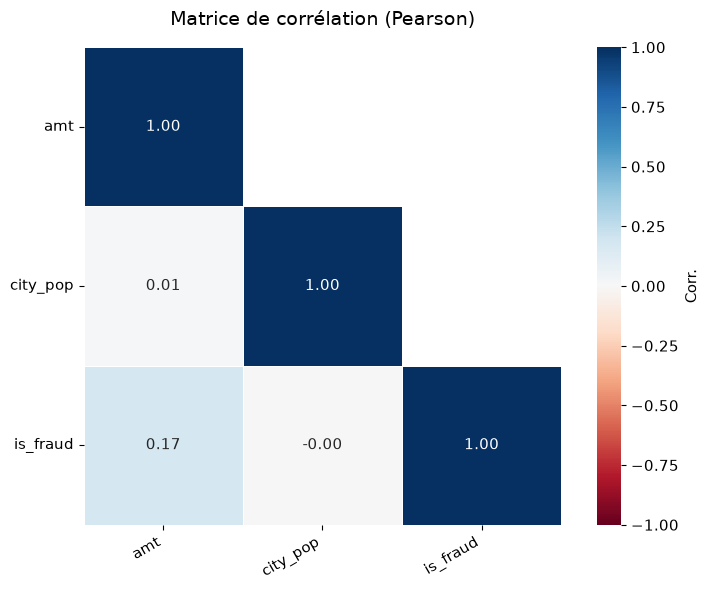

In [53]:
fig_corr, matrice_corr = heatmap_correlation_triangulaire(
    df=df_copy,
    variables=["amt","city_pop","is_fraud"],
    methode="pearson"
)

fig_corr.show()

**Heatmap des corrélations (Spearman)**

/tmp/ipykernel_33186/551345277.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_corr.show()


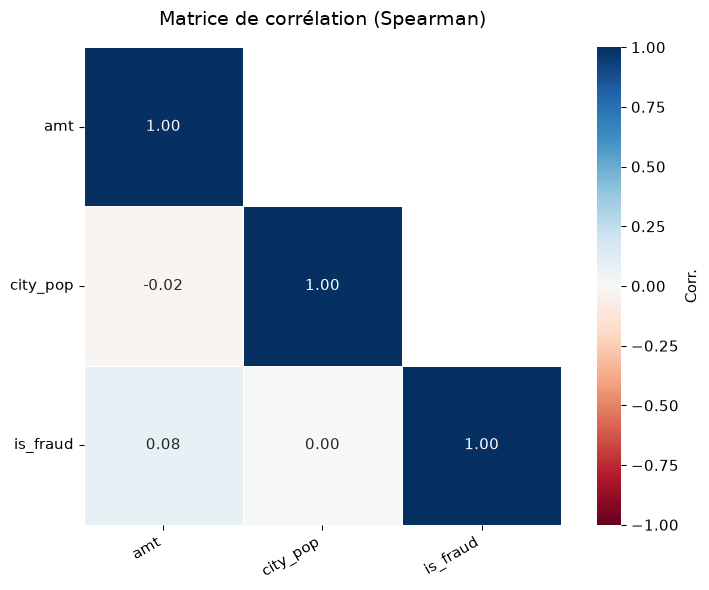

In [54]:
fig_corr, matrice_corr = heatmap_correlation_triangulaire(
    df=df_copy,
    variables=["amt","city_pop","is_fraud"],
    methode="spearman"
)

fig_corr.show()

### 2.B Numériques | Cible

**Check des distributions en fonction de la variable cible**

(<Figure size 1100x450 with 2 Axes>,
    variable  groupe      n     moyenne  mediane   ecart_type    min  \
 0       amt       0  49740     67.9168    47.35     182.6990   1.00   
 1       amt       1    261    517.1410   346.60     391.4148   6.76   
 2  city_pop       0  49740  89668.7209  2408.00  305761.1713  23.00   
 3  city_pop       1    261  84486.5977  3164.00  318711.8423  49.00   
 
             max  
 0  2.711977e+04  
 1  1.276770e+03  
 2  2.906700e+06  
 3  2.906700e+06  )

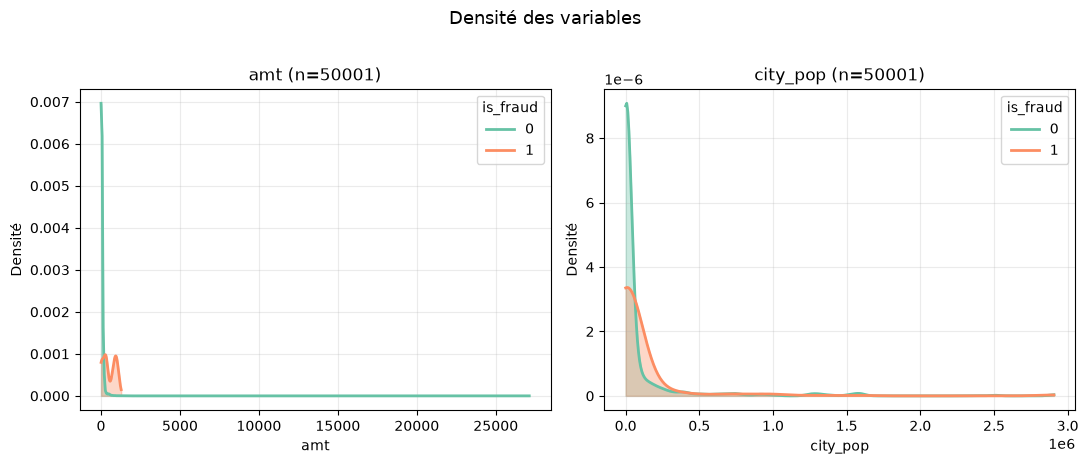

In [67]:
plot_densites(
    df=df_copy,
    colonnes=colonnes_num,
    hue="is_fraud"
)

**Test de Mann Whitney U**

In [71]:
test_mann_whitney_multi(
    df=df_copy,
    var_numeriques=colonnes_num,
    var_binaires="is_fraud"
)

,variable_numerique,variable_binaire,groupe1,groupe2,n1,n2,mediane1,mediane2,statistique_U,p_value,seuil,significatif,r,sens_effet
0,amt,is_fraud,0,1,49740,261,47.35,346.6,2155136.0,0.000000,0.05,True,-0.083371,negatif
1,city_pop,is_fraud,0,1,49740,261,2408.00,3164.0,6386584.5,0.653259,0.05,False,-0.002009,negatif


### 2.C Catégorielles | Cible

**Check des modalités en fonction de la variable cible**

In [12]:
df_copy.query("is_fraud==1").filter(["category"]).value_counts()
# df_copy.query("is_fraud==1").filter(["city"]).value_counts()
# df_copy.query("is_fraud==1").filter(["state"]).value_counts()
# df_copy.query("is_fraud==1").filter(["merchant"]).value_counts()
# df_copy.query("is_fraud==1").filter(["job"]).value_counts()

category      
grocery_pos       65
shopping_net      59
misc_net          29
shopping_pos      27
gas_transport     23
personal_care     11
home               9
misc_pos           8
entertainment      7
food_dining        6
grocery_net        6
kids_pets          4
travel             4
health_fitness     3
Name: count, dtype: int64

(<Figure size 550x450 with 1 Axes>,
    variable      n  nb_categories  nb_manquants categorie_dominante  \
 0  category  50001             14             0       gas_transport   
 
    freq_dominante  
 0          0.1004  )

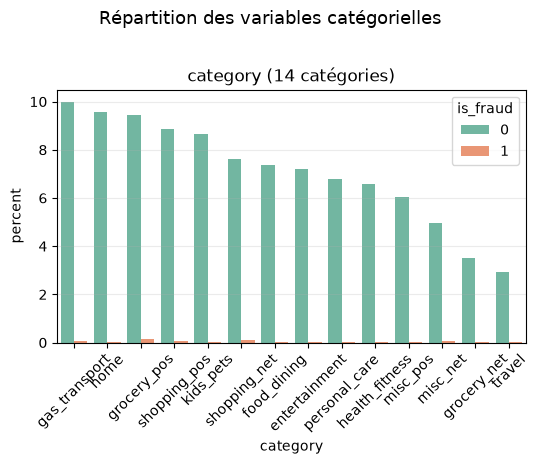

In [72]:
plot_countplots(df=df_copy,
                colonnes=["category"],
                hue="is_fraud",
                order_by_freq=True,
                stat="percent")

**Test de Khi²**

In [86]:
khi2_resultat = analyse_contingence_multi(
    df=df_copy,
    var_lignes=colonnes_cat,
    var_colonnes="is_fraud"
)

khi2_resultat[0]

,var1,var2,chi2,dof,p_value,seuil,significatif,V_cramer,n_observations
0,merchant,is_fraud,892.0283,692,0.0000,0.05,True,0.1336,50001
1,category,is_fraud,224.0174,13,0.0000,0.05,True,0.0669,50001
2,city,is_fraud,5509.4872,857,0.0000,0.05,True,0.3319,50001
3,state,is_fraud,54.6511,49,0.2686,0.05,False,0.0331,50001
4,job,is_fraud,2784.9264,484,0.0000,0.05,True,0.2360,50001


# Feature Engineering

In [50]:
df_copy.sample(7)

,id,trans_date_trans_time,merchant,category,amt,city,state,lat,long,city_pop,job,dob,merch_lat,merch_long,is_fraud
30663,30664,2019-07-06 08:24:21,Luettgen PLC,gas_transport,67.260002,Mooresville,NC,35.584000,-80.868500,69793,Control and instrumentation engineer,1953-12-08,35.074230,-81.784256,0
5157,5158,2019-06-26 08:20:52,Botsford Ltd,shopping_pos,3.740000,Broomfield,CO,39.885399,-105.113899,92337,"Engineer, electronics",1967-10-18,40.654793,-105.007393,0
33888,33889,2019-07-01 23:35:17,Fritsch and Sons,health_fitness,21.580000,Falconer,NY,42.123901,-79.189499,3833,Metallurgist,1970-10-09,42.609917,-79.001160,0
28454,28455,2019-05-23 05:06:20,Welch Inc,misc_net,81.529999,Tupper Lake,NY,44.231998,-74.490501,6120,Chartered loss adjuster,1976-10-09,43.433586,-73.743652,0
671,672,2020-05-10 09:00:20,Block Group,misc_pos,2.250000,Columbia,SC,33.965900,-80.935501,333497,Mechanical engineer,1968-03-19,33.863762,-81.904663,0
36879,36880,2020-03-13 10:20:33,Welch Inc,misc_net,65.040001,June Lake,CA,37.777302,-119.082497,633,Health service manager,1927-09-09,37.824047,-118.128609,0
1770,1771,2019-02-22 02:23:54,Lockman Ltd,grocery_pos,108.430000,Hewitt,WI,44.643700,-90.103104,828,Arts development officer,1991-08-19,44.746300,-89.671722,0


In [51]:
df_copy.filter(["city"]).value_counts()

city       
Birmingham     208
Utica          200
Phoenix        199
San Antonio    195
Arcadia        182
              ... 
Phelps           1
Gaines           1
Angwin           1
Lexington        1
Guthrie          1
Name: count, Length: 858, dtype: int64

In [52]:
df_copy.query("is_fraud==1").filter(["state"]).value_counts().reset_index()

,state,count
0,NY,21
1,CA,19
2,TX,17
3,OH,11
4,SC,9
5,TN,9
6,IL,9
7,PA,9
8,FL,8
9,OK,8


In [23]:
stats_category = df_copy.query("is_fraud==1").filter(["category"]).value_counts().reset_index()
stats_state = df_copy.query("is_fraud==1").filter(["state"]).value_counts().reset_index()

In [24]:
#stats_category
stats_state

,state,count
0,NY,21
1,CA,19
2,TX,17
3,OH,11
4,SC,9
5,TN,9
6,IL,9
7,PA,9
8,FL,8
9,OK,8


In [18]:
for q in [0.25,0.5,0.75]:
    print(np.quantile(stats_category["count"],q))

6.0
8.5
26.0


In [25]:
for q in [0.25,0.5,0.75]:
    print(np.quantile(stats_state["count"],q))

2.0
4.5
6.75


In [26]:
for q in [0.25,0.5,0.75]:
    print(np.quantile(df_copy["city_pop"],q))

737.0
2408.0
19685.0


**Variables temporelles**

`jour` représente le jour de la semaine en anglais, ordonné du lundi au dimanche.
`heure` varie de 0 à 23.

In [177]:
date_transaction = pd.to_datetime(df_copy["trans_date_trans_time"], errors="raise")
jours_ordonnes = [
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"
]

df_copy["annee"] = date_transaction.dt.year.astype("Int16")
df_copy["mois"] = date_transaction.dt.month.astype("Int8")
df_copy["jour"] = pd.Categorical(
    date_transaction.dt.dayofweek.map(dict(enumerate(jours_ordonnes))),
    categories=jours_ordonnes,
    ordered=True,
)
df_copy["heure"] = date_transaction.dt.hour.astype("Int8")

**Âge de l'acheteur à la date de la transaction**

Âge en années révolues : on retire une année si l'anniversaire n'a pas encore eu
lieu à la date de la transaction. Pour une naissance le 29 février, cette convention
fait passer à l'âge suivant le 1er mars les années non bissextiles.

In [178]:
date_naissance = pd.to_datetime(df_copy["dob"], errors="raise")
anniversaire_a_venir = (
    (date_transaction.dt.month < date_naissance.dt.month)
    | (
        (date_transaction.dt.month == date_naissance.dt.month)
        & (date_transaction.dt.day < date_naissance.dt.day)
    )
)
df_copy["age"] = (
    date_transaction.dt.year
    - date_naissance.dt.year
    - anniversaire_a_venir.astype("int8")
).astype("Int16")

**Distance entre l'acheteur et le magasin**

Distance à vol d'oiseau en kilomètres, calculée par la formule de Haversine
avec un rayon terrestre moyen de 6 371,0088 km. Il ne s'agit pas d'une distance routière.
Les coordonnées sont converties en `float64` avant le calcul.

In [179]:
lat_acheteur = np.radians(df_copy["lat"].astype("float64"))
long_acheteur = np.radians(df_copy["long"].astype("float64"))
lat_magasin = np.radians(df_copy["merch_lat"].astype("float64"))
long_magasin = np.radians(df_copy["merch_long"].astype("float64"))

delta_lat = lat_magasin - lat_acheteur
delta_long = long_magasin - long_acheteur
a_haversine = (
    np.sin(delta_lat / 2) ** 2
    + np.cos(lat_acheteur) * np.cos(lat_magasin) * np.sin(delta_long / 2) ** 2
)
df_copy["distance_acheteur_magasin_km"] = (
    2 * 6371.0088 * np.arcsin(np.sqrt(a_haversine.clip(0, 1)))
)

**Statistiques de fraude par heure, jour, catégorie et État**

Pour chaque modalité de `heure`, `jour`, `category` et `state`, on reporte dans
`df_copy` les trois statistiques suivantes, identiques pour toutes les transactions
appartenant à cette modalité :

- `nb_transactions_<variable>` : nombre total de transactions, fraudes incluses ;
- `nb_fraudes_<variable>` : nombre de transactions pour lesquelles `is_fraud = 1` ;
- `taux_fraude_<variable>` : `nb_fraudes / nb_transactions`, entre 0 et 1.

Ces 12 colonnes numériques servent de base au calcul manuel des niveaux de risque.
Les modalités sans fraude ont un nombre de fraudes et un taux égaux à zéro.
Une modalité manquante conserve des statistiques manquantes.


In [180]:
from IPython.display import display

variables_stats_fraude = ["heure", "jour", "category", "state"]
colonnes_stats_fraude = []

for variable_stats in variables_stats_fraude:
    fraudes_du_groupe = df_copy.groupby(variable_stats, observed=True)["is_fraud"]
    colonne_effectif = f"nb_transactions_{variable_stats}"
    colonne_fraudes = f"nb_fraudes_{variable_stats}"
    colonne_taux = f"taux_fraude_{variable_stats}"

    # transform conserve l'ordre et l'index des transactions dans df_copy.
    df_copy[colonne_effectif] = fraudes_du_groupe.transform("size").astype("Int64")
    df_copy[colonne_fraudes] = fraudes_du_groupe.transform("sum").astype("Int64")
    df_copy[colonne_taux] = df_copy[colonne_fraudes] / df_copy[colonne_effectif]
    colonnes_stats_fraude.extend([colonne_effectif, colonne_fraudes, colonne_taux])

display(df_copy[variables_stats_fraude + colonnes_stats_fraude].head())


,heure,jour,category,state,nb_transactions_heure,nb_fraudes_heure,taux_fraude_heure,nb_transactions_jour,nb_fraudes_jour,taux_fraude_jour,nb_transactions_category,nb_fraudes_category,taux_fraude_category,nb_transactions_state,nb_fraudes_state,taux_fraude_state
0,22,Friday,kids_pets,MI,2630,70,0.026616,5832,28,0.004801,4333,4,0.000923,1683,7,0.004159
1,11,Thursday,grocery_pos,FL,1655,1,0.000604,5623,34,0.006047,4777,65,0.013607,1662,8,0.004813
2,2,Monday,grocery_pos,MD,1649,20,0.012129,10071,47,0.004667,4777,65,0.013607,1035,4,0.003865
3,16,Monday,personal_care,UT,2615,3,0.001147,10071,47,0.004667,3413,11,0.003223,431,1,0.00232
4,22,Wednesday,misc_pos,CA,2630,70,0.026616,4925,34,0.006904,3025,8,0.002645,2169,19,0.00876


In [98]:
kmeans_discretizer = KBinsDiscretizer(
    n_bins=4,
    encode="ordinal",            
    strategy="kmeans",        
)

kmeans_discretizer.fit(df_copy.filter(["taux_fraude_state"]))

,"n_bins n_bins: int or array-like of shape (n_features,), default=5The number of bins to produce. Raises ValueError if ``n_bins < 2``.",4
,"encode encode: {'onehot', 'onehot-dense', 'ordinal'}, default='onehot'Method used to encode the transformed result.- 'onehot': Encode the transformed result with one-hot encoding and return a sparse matrix. Ignored features are always stacked to the right.- 'onehot-dense': Encode the transformed result with one-hot encoding and return a dense array. Ignored features are always stacked to the right.- 'ordinal': Return the bin identifier encoded as an integer value.",'ordinal'
,"strategy strategy: {'uniform', 'quantile', 'kmeans'}, default='quantile'Strategy used to define the widths of the bins.- 'uniform': All bins in each feature have identical widths.- 'quantile': All bins in each feature have the same number of points.- 'kmeans': Values in each bin have the same nearest center of a 1D k-means cluster.For an example of the different strategies see::ref:`sphx_glr_auto_examples_preprocessing_plot_discretization_strategies.py`.",'kmeans'
,"quantile_method quantile_method: {""inverted_cdf"", ""averaged_inverted_cdf"",""closest_observation"", ""interpolated_inverted_cdf"", ""hazen"",""weibull"", ""linear"", ""median_unbiased"", ""normal_unbiased""},default=""averaged_inverted_cdf""Method to pass on to np.percentile calculation when usingstrategy=""quantile"". Only `averaged_inverted_cdf` and `inverted_cdf`support the use of `sample_weight != None` when subsampling is notactive... versionadded:: 1.7.. versionchanged:: 1.9 The default value changed from `""linear""` to `""averaged_inverted_cdf""`.",'averaged_inverted_cdf'
,"dtype dtype: {np.float32, np.float64}, default=NoneThe desired data-type for the output. If None, output dtype isconsistent with input dtype. Only np.float32 and np.float64 aresupported... versionadded:: 0.24",None
,"subsample subsample: int or None, default=200_000Maximum number of samples, used to fit the model, for computationalefficiency.`subsample=None` means that all the training samples are used whencomputing the quantiles that determine the binning thresholds.Since quantile computation relies on sorting each column of `X` andthat sorting has an `n log(n)` time complexity,it is recommended to use subsampling on datasets with avery large number of samples... versionchanged:: 1.3 The default value of `subsample` changed from `None` to `200_000` when `strategy=""quantile""`... versionchanged:: 1.5 The default value of `subsample` changed from `None` to `200_000` when `strategy=""uniform""` or `strategy=""kmeans""`.",200000
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for subsampling.Pass an int for reproducible results across multiple function calls.See the `subsample` parameter for more details.See :term:`Glossary <random_state>`... versionadded:: 1.1",None
Name,Type,Value
"bin_edges_ bin_edges_: ndarray of ndarray of shape (n_features,)The edges of each bin. Contain arrays of varying shapes ``(n_bins_, )``Ignored features will have empty arrays.","ndarray[object](1,)","[array([0. , 0.005392 , 0.00983247, 0.01710862, 0.02150538])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['taux_fraude_state']
"n_bins_ n_bins_: ndarray of shape (n_features,), dtype=np.int64Number of bins per feature. Bins whose width are too small(i.e., <= 1e-8) are removed with a warning.","ndarray[int64](1,)",[4]


In [137]:
quantile_discretizer = KBinsDiscretizer(
    n_bins=4,
    encode="ordinal",            
    strategy="quantile",        
)

quantile_discretizer.fit(df_copy.filter(["distance_acheteur_magasin_km"]))

,"n_bins n_bins: int or array-like of shape (n_features,), default=5The number of bins to produce. Raises ValueError if ``n_bins < 2``.",4
,"encode encode: {'onehot', 'onehot-dense', 'ordinal'}, default='onehot'Method used to encode the transformed result.- 'onehot': Encode the transformed result with one-hot encoding and return a sparse matrix. Ignored features are always stacked to the right.- 'onehot-dense': Encode the transformed result with one-hot encoding and return a dense array. Ignored features are always stacked to the right.- 'ordinal': Return the bin identifier encoded as an integer value.",'ordinal'
,"strategy strategy: {'uniform', 'quantile', 'kmeans'}, default='quantile'Strategy used to define the widths of the bins.- 'uniform': All bins in each feature have identical widths.- 'quantile': All bins in each feature have the same number of points.- 'kmeans': Values in each bin have the same nearest center of a 1D k-means cluster.For an example of the different strategies see::ref:`sphx_glr_auto_examples_preprocessing_plot_discretization_strategies.py`.",'quantile'
,"quantile_method quantile_method: {""inverted_cdf"", ""averaged_inverted_cdf"",""closest_observation"", ""interpolated_inverted_cdf"", ""hazen"",""weibull"", ""linear"", ""median_unbiased"", ""normal_unbiased""},default=""averaged_inverted_cdf""Method to pass on to np.percentile calculation when usingstrategy=""quantile"". Only `averaged_inverted_cdf` and `inverted_cdf`support the use of `sample_weight != None` when subsampling is notactive... versionadded:: 1.7.. versionchanged:: 1.9 The default value changed from `""linear""` to `""averaged_inverted_cdf""`.",'averaged_inverted_cdf'
,"dtype dtype: {np.float32, np.float64}, default=NoneThe desired data-type for the output. If None, output dtype isconsistent with input dtype. Only np.float32 and np.float64 aresupported... versionadded:: 0.24",None
,"subsample subsample: int or None, default=200_000Maximum number of samples, used to fit the model, for computationalefficiency.`subsample=None` means that all the training samples are used whencomputing the quantiles that determine the binning thresholds.Since quantile computation relies on sorting each column of `X` andthat sorting has an `n log(n)` time complexity,it is recommended to use subsampling on datasets with avery large number of samples... versionchanged:: 1.3 The default value of `subsample` changed from `None` to `200_000` when `strategy=""quantile""`... versionchanged:: 1.5 The default value of `subsample` changed from `None` to `200_000` when `strategy=""uniform""` or `strategy=""kmeans""`.",200000
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for subsampling.Pass an int for reproducible results across multiple function calls.See the `subsample` parameter for more details.See :term:`Glossary <random_state>`... versionadded:: 1.1",None
Name,Type,Value
"bin_edges_ bin_edges_: ndarray of ndarray of shape (n_features,)The edges of each bin. Contain arrays of varying shapes ``(n_bins_, )``Ignored features will have empty arrays.","ndarray[object](1,)","[array([ 0.19987214, 54.82825439, 77.84869635, 98.23133961, 147.43839309]) ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['distance_acheteur_magasin_km']
"n_bins_ n_bins_: ndarray of shape (n_features,), dtype=np.int64Number of bins per feature. Bins whose width are too small(i.e., <= 1e-8) are removed with a warning.","ndarray[int64](1,)",[4]


In [138]:
df_copy = df_copy.assign(
    
    quantile_risque_distance = quantile_discretizer.transform(df_copy.filter(["distance_acheteur_magasin_km"]).to_numpy().copy())

)

/home/user_daren_mabanza/data_science/projets/V2_projet_fraud_detection/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but KBinsDiscretizer was fitted with feature names
  warnings.warn(


(<Figure size 550x450 with 1 Axes>,
                    variable      n  nb_categories  nb_manquants  \
 0  quantile_risque_distance  50001              4             0   
 
    categorie_dominante  freq_dominante  
 0                  3.0            0.25  )

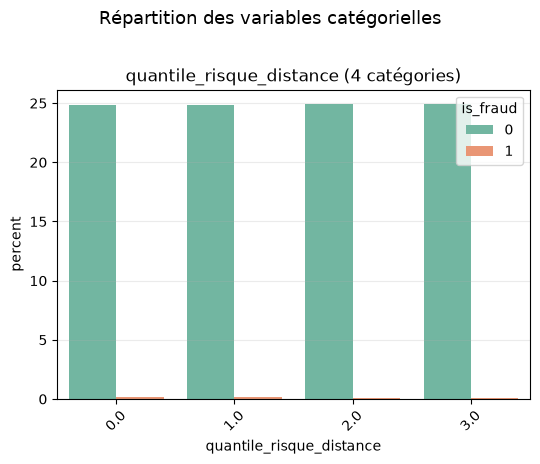

In [139]:
plot_countplots(df=df_copy,
                colonnes=["quantile_risque_distance"],
                hue="is_fraud",
                order_by_freq=False,
                stat="percent")

In [140]:
df_copy.query("is_fraud==1").filter(["quantile_risque_distance"]).value_counts()

quantile_risque_distance
1.0                         86
0.0                         64
2.0                         57
3.0                         54
Name: count, dtype: int64

In [141]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 50001 entries, 0 to 50000
Data columns (total 43 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   id                            50001 non-null  uint32        
 1   trans_date_trans_time         50001 non-null  datetime64[us]
 2   merchant                      50001 non-null  category      
 3   category                      50001 non-null  category      
 4   amt                           50001 non-null  float32       
 5   city                          50001 non-null  category      
 6   state                         50001 non-null  category      
 7   lat                           50001 non-null  float32       
 8   long                          50001 non-null  float32       
 9   city_pop                      50001 non-null  uint32        
 10  job                           50001 non-null  category      
 11  dob                           50001 non

In [9]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 50001 entries, 0 to 50000
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     50001 non-null  uint32        
 1   trans_date_trans_time  50001 non-null  datetime64[us]
 2   merchant               50001 non-null  category      
 3   category               50001 non-null  category      
 4   amt                    50001 non-null  float32       
 5   city                   50001 non-null  category      
 6   state                  50001 non-null  category      
 7   lat                    50001 non-null  float32       
 8   long                   50001 non-null  float32       
 9   city_pop               50001 non-null  uint32        
 10  job                    50001 non-null  category      
 11  dob                    50001 non-null  datetime64[us]
 12  merch_lat              50001 non-null  float32       
 13  merch_long  

In [172]:
isolation_forest = IsolationForest(
    n_estimators=300,
    contamination=0.07,
    max_samples="auto",
    max_features=1.0,
    bootstrap=False,
    n_jobs=-1,
    random_state=42,
)

ohe = OneHotEncoder(
    categories="auto",
    drop=None,                  
    handle_unknown="error",     
    sparse_output=False
)

In [173]:
model_cols = df_copy.filter(["amt","quantile_risque_heure","quantile_risque_jour","quantile_risque_category","quantile_risque_state"])

ValueError: cannot reindex on an axis with duplicate labels

In [157]:
ohe_cat_cols = pd.DataFrame(
    ohe.fit_transform(model_cols.filter(["quantile_risque_heure","quantile_risque_jour","quantile_risque_category","quantile_risque_state"])),
    columns=ohe.get_feature_names_out()
)

model_cols_V2 = pd.concat([df_copy.filter(["amt"]),ohe_cat_cols],
                          axis=1)

In [158]:
model_cols_V2.head(6)

,amt,quantile_risque_heure_0.0,quantile_risque_heure_1.0,quantile_risque_heure_2.0,quantile_risque_heure_3.0,quantile_risque_jour_0.0,quantile_risque_jour_1.0,quantile_risque_jour_2.0,quantile_risque_jour_3.0,quantile_risque_category_0.0,quantile_risque_category_1.0,quantile_risque_category_2.0,quantile_risque_category_3.0,quantile_risque_state_0.0,quantile_risque_state_1.0,quantile_risque_state_2.0,quantile_risque_state_3.0
0,109.790001,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,162.580002,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,38.240002,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3,85.930000,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,6.260000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
5,4.930000,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [159]:
isolation_forest.fit(model_cols_V2)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",300
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.07
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [166]:
if_score = pd.DataFrame(-isolation_forest.decision_function(model_cols_V2), columns=["score_anomalie"])

In [167]:
models_cols_V3 = pd.concat([model_cols_V2,if_score], axis=1)

In [168]:
models_cols_V3.sample(5)

,amt,quantile_risque_heure_0.0,quantile_risque_heure_1.0,quantile_risque_heure_2.0,quantile_risque_heure_3.0,quantile_risque_jour_0.0,quantile_risque_jour_1.0,quantile_risque_jour_2.0,quantile_risque_jour_3.0,quantile_risque_category_0.0,quantile_risque_category_1.0,quantile_risque_category_2.0,quantile_risque_category_3.0,quantile_risque_state_0.0,quantile_risque_state_1.0,quantile_risque_state_2.0,quantile_risque_state_3.0,score_anomalie
42807,10.830000,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.001879
5965,119.639999,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.031564
29261,61.400002,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,-0.017701
43477,39.950001,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.031059
25722,33.360001,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.020907


In [169]:
df_copy = pd.concat([df_copy,if_score], axis=1)

# Après Feature Engineering

## 1. Analyse univariée

### 1.A Variables numériques

In [170]:
new_colonnes_num = ["score_anomalie"]

In [171]:
plot_densites(df=df_copy,
              colonnes=new_colonnes_num,
              ncols=4)

TypeError: La variable 'score_anomalie' doit être numérique.

### 1.B Variables catégorielles 

In [116]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 50001 entries, 0 to 50000
Data columns (total 39 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   id                            50001 non-null  uint32        
 1   trans_date_trans_time         50001 non-null  datetime64[us]
 2   merchant                      50001 non-null  category      
 3   category                      50001 non-null  category      
 4   amt                           50001 non-null  float32       
 5   city                          50001 non-null  category      
 6   state                         50001 non-null  category      
 7   lat                           50001 non-null  float32       
 8   long                          50001 non-null  float32       
 9   city_pop                      50001 non-null  uint32        
 10  job                           50001 non-null  category      
 11  dob                           50001 non

In [46]:
new_colonnes_cat = ["annee","mois","jour","heure",
                    "risque_heure","risque_jour","risque_category","risque_state"]

(<Figure size 1650x1350 with 9 Axes>,
           variable      n  nb_categories  nb_manquants categorie_dominante  \
 0            annee  50001              2             0                2020   
 1             mois  50001             12             0                  12   
 2             jour  50001              7             0              Monday   
 3            heure  50001             24             0                  22   
 4     risque_heure  50001              4             0              faible   
 5      risque_jour  50001              4             0         tres_faible   
 6  risque_category  50001              4             0         tres_faible   
 7     risque_state  50001              4             0             moderee   
 
    freq_dominante  
 0          0.5007  
 1          0.1525  
 2          0.2014  
 3          0.0526  
 4          0.2845  
 5          0.3426  
 6          0.3224  
 7          0.3047  )

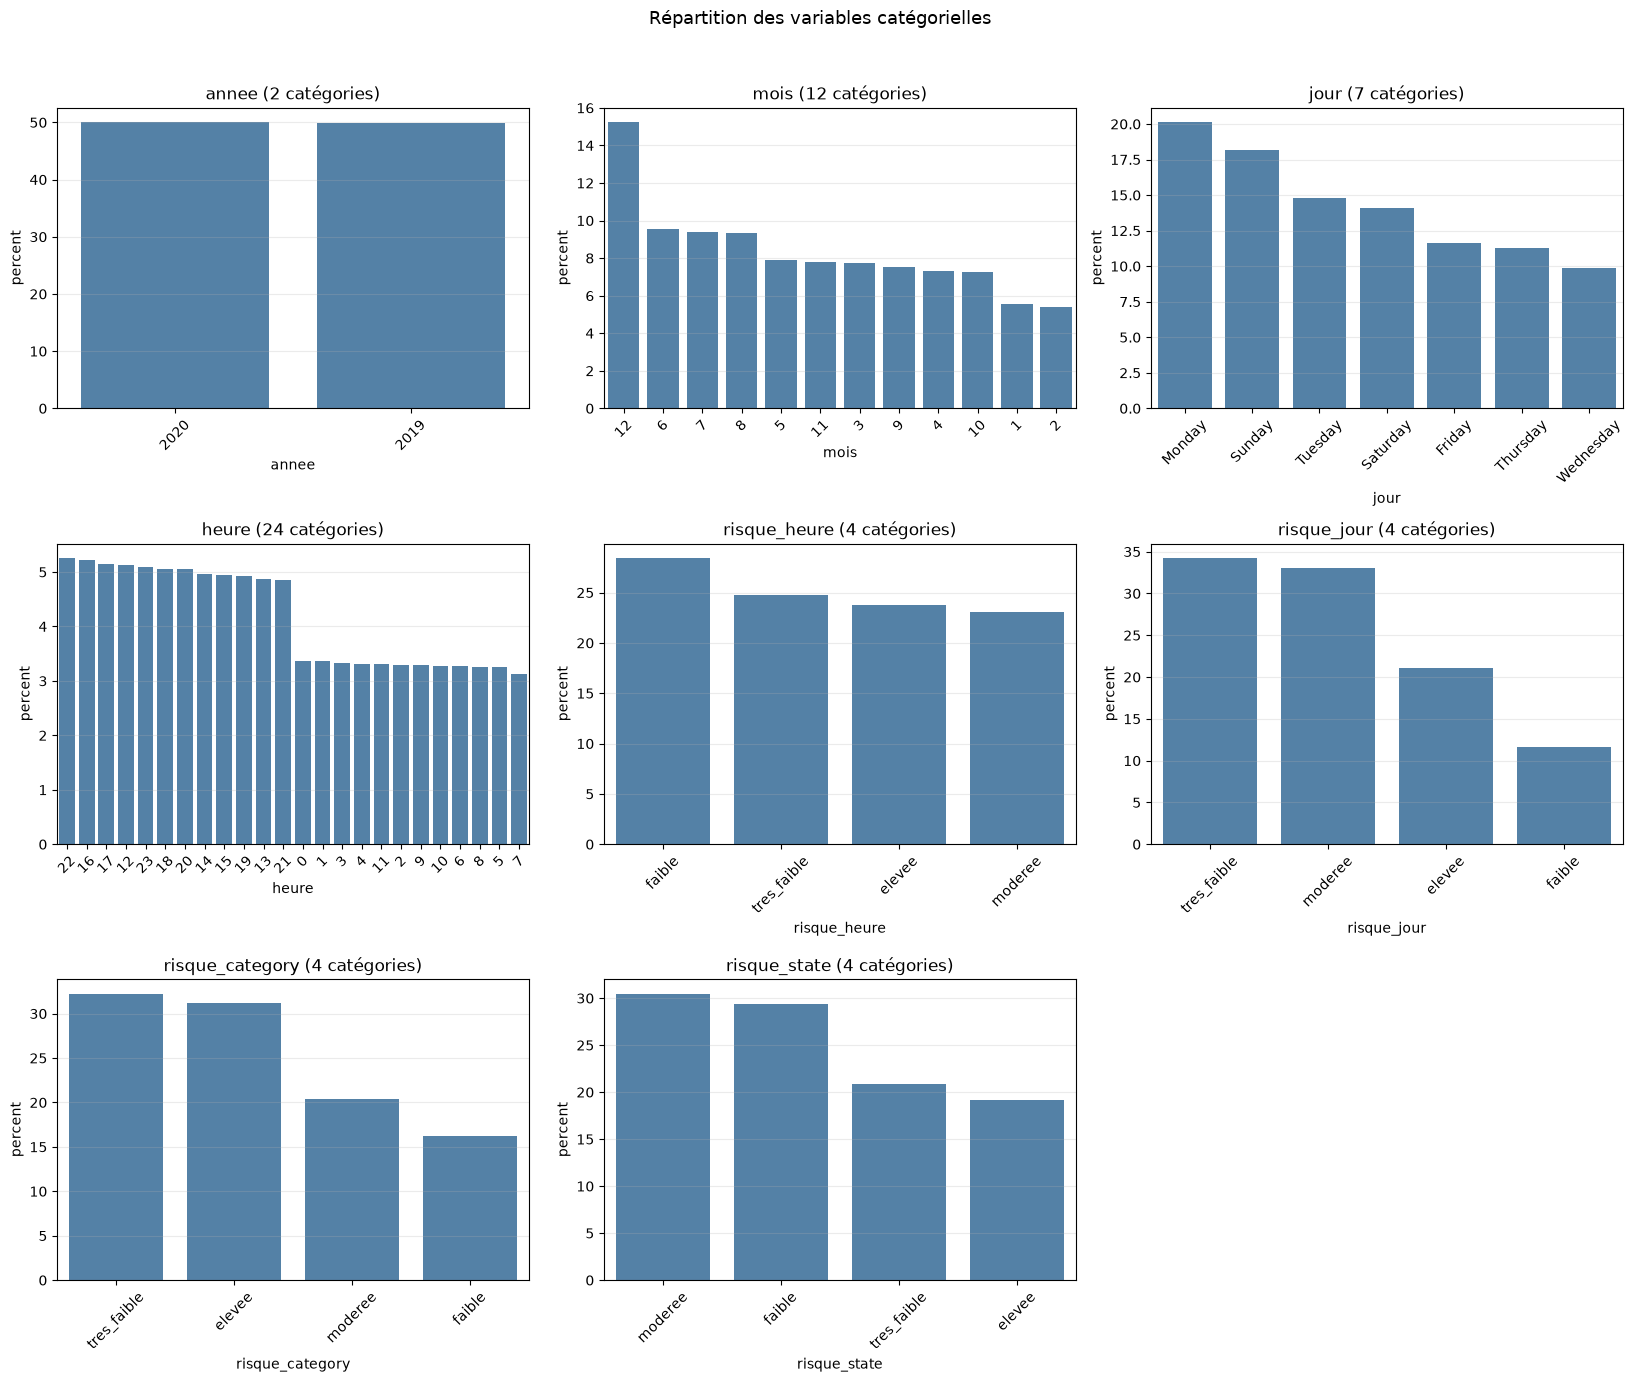

In [47]:
plot_countplots(df=df_copy,
                colonnes=new_colonnes_cat,
                order_by_freq=True,
                stat="percent")

## 2. Analyse bivariée

### Numériques | Numériques 

/home/user_daren_mabanza/data_science/projets/V2_projet_fraud_detection/.venv/lib/python3.14/site-packages/seaborn/matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)
/tmp/ipykernel_33186/3539452601.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_corr.show()


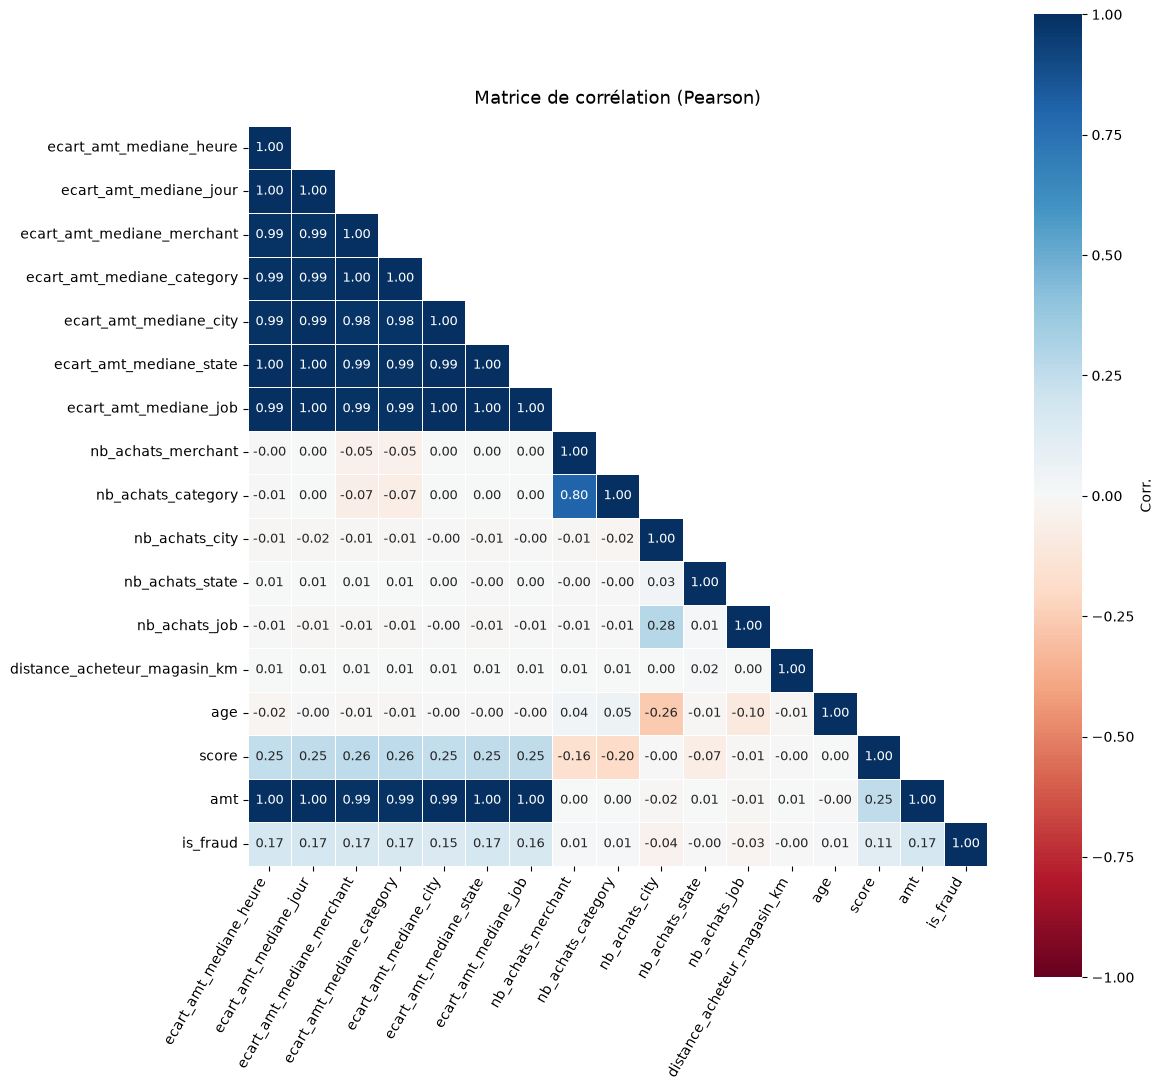

In [117]:
fig_corr, matrice_corr = heatmap_correlation_triangulaire(
    df=df_copy,
    variables=new_colonnes_num+["amt","is_fraud"],
    methode="pearson"
)

fig_corr.show()

/home/user_daren_mabanza/data_science/projets/V2_projet_fraud_detection/.venv/lib/python3.14/site-packages/seaborn/matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)
/tmp/ipykernel_33186/1367040668.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_corr.show()


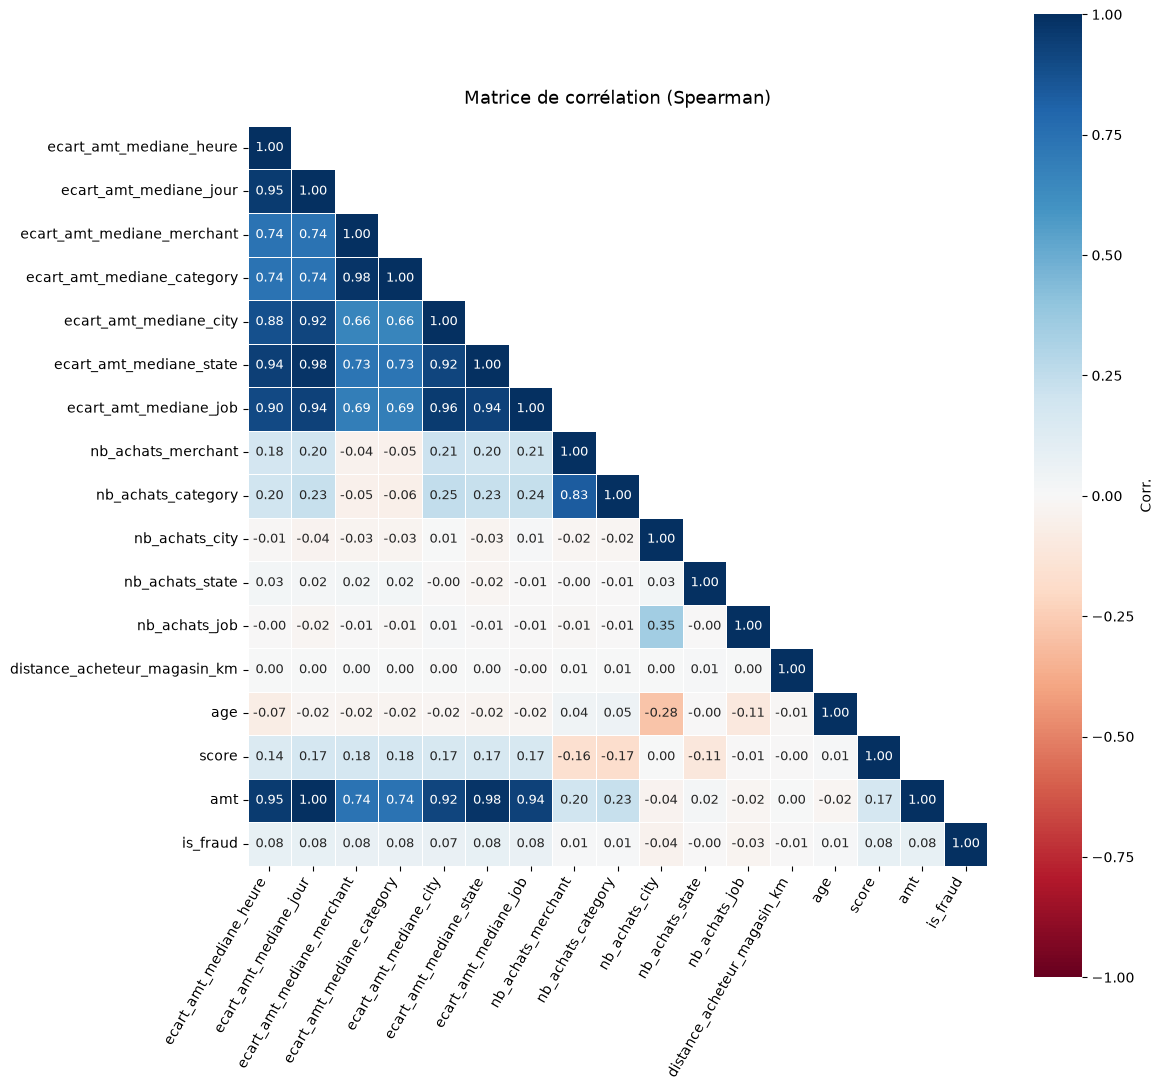

In [118]:
fig_corr, matrice_corr = heatmap_correlation_triangulaire(
    df=df_copy,
    variables=new_colonnes_num+["amt","is_fraud"],
    methode="spearman"
)

fig_corr.show()

### Numériques | Cible

(<Figure size 550x450 with 1 Axes>,
          variable  groupe      n  moyenne  mediane  ecart_type     min     max
 0  score_anomalie       0  49740  -0.0452  -0.0481      0.0188 -0.0879  0.0554
 1  score_anomalie       1    261  -0.0118  -0.0087      0.0299 -0.0698  0.0527)

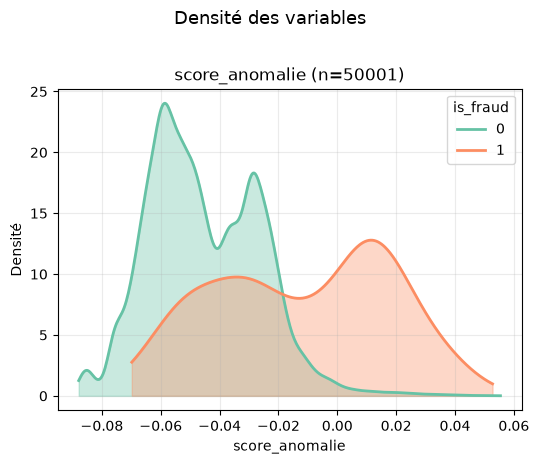

In [153]:
plot_densites(
    df=df_copy,
    colonnes=new_colonnes_num,
    hue="is_fraud"
)

In [154]:
test_mann_whitney_multi(
    df=df_copy,
    var_numeriques=new_colonnes_num,
    var_binaires="is_fraud"
)

,variable_numerique,variable_binaire,groupe1,groupe2,n1,n2,mediane1,mediane2,statistique_U,p_value,seuil,significatif,r,sens_effet
0,score_anomalie,is_fraud,0,1,49740,261,-0.0481,-0.0087,2473646.5,7.494758e-67,0.05,True,-0.077247,negatif


### Catégorielles | Cible

(<Figure size 1650x1350 with 9 Axes>,
             variable      n  nb_categories  nb_manquants categorie_dominante  \
 0               jour  50001              7             0              Monday   
 1              heure  50001             24             0                  22   
 2       risque_heure  50001              4             0              faible   
 3        risque_jour  50001              4             0         tres_faible   
 4    risque_category  50001              4             0         tres_faible   
 5       risque_state  50001              4             0             moderee   
 6  niveau_population  50001              4             0              elevee   
 
    freq_dominante  
 0          0.2014  
 1          0.0526  
 2          0.2845  
 3          0.3426  
 4          0.3224  
 5          0.3047  
 6          0.2519  )

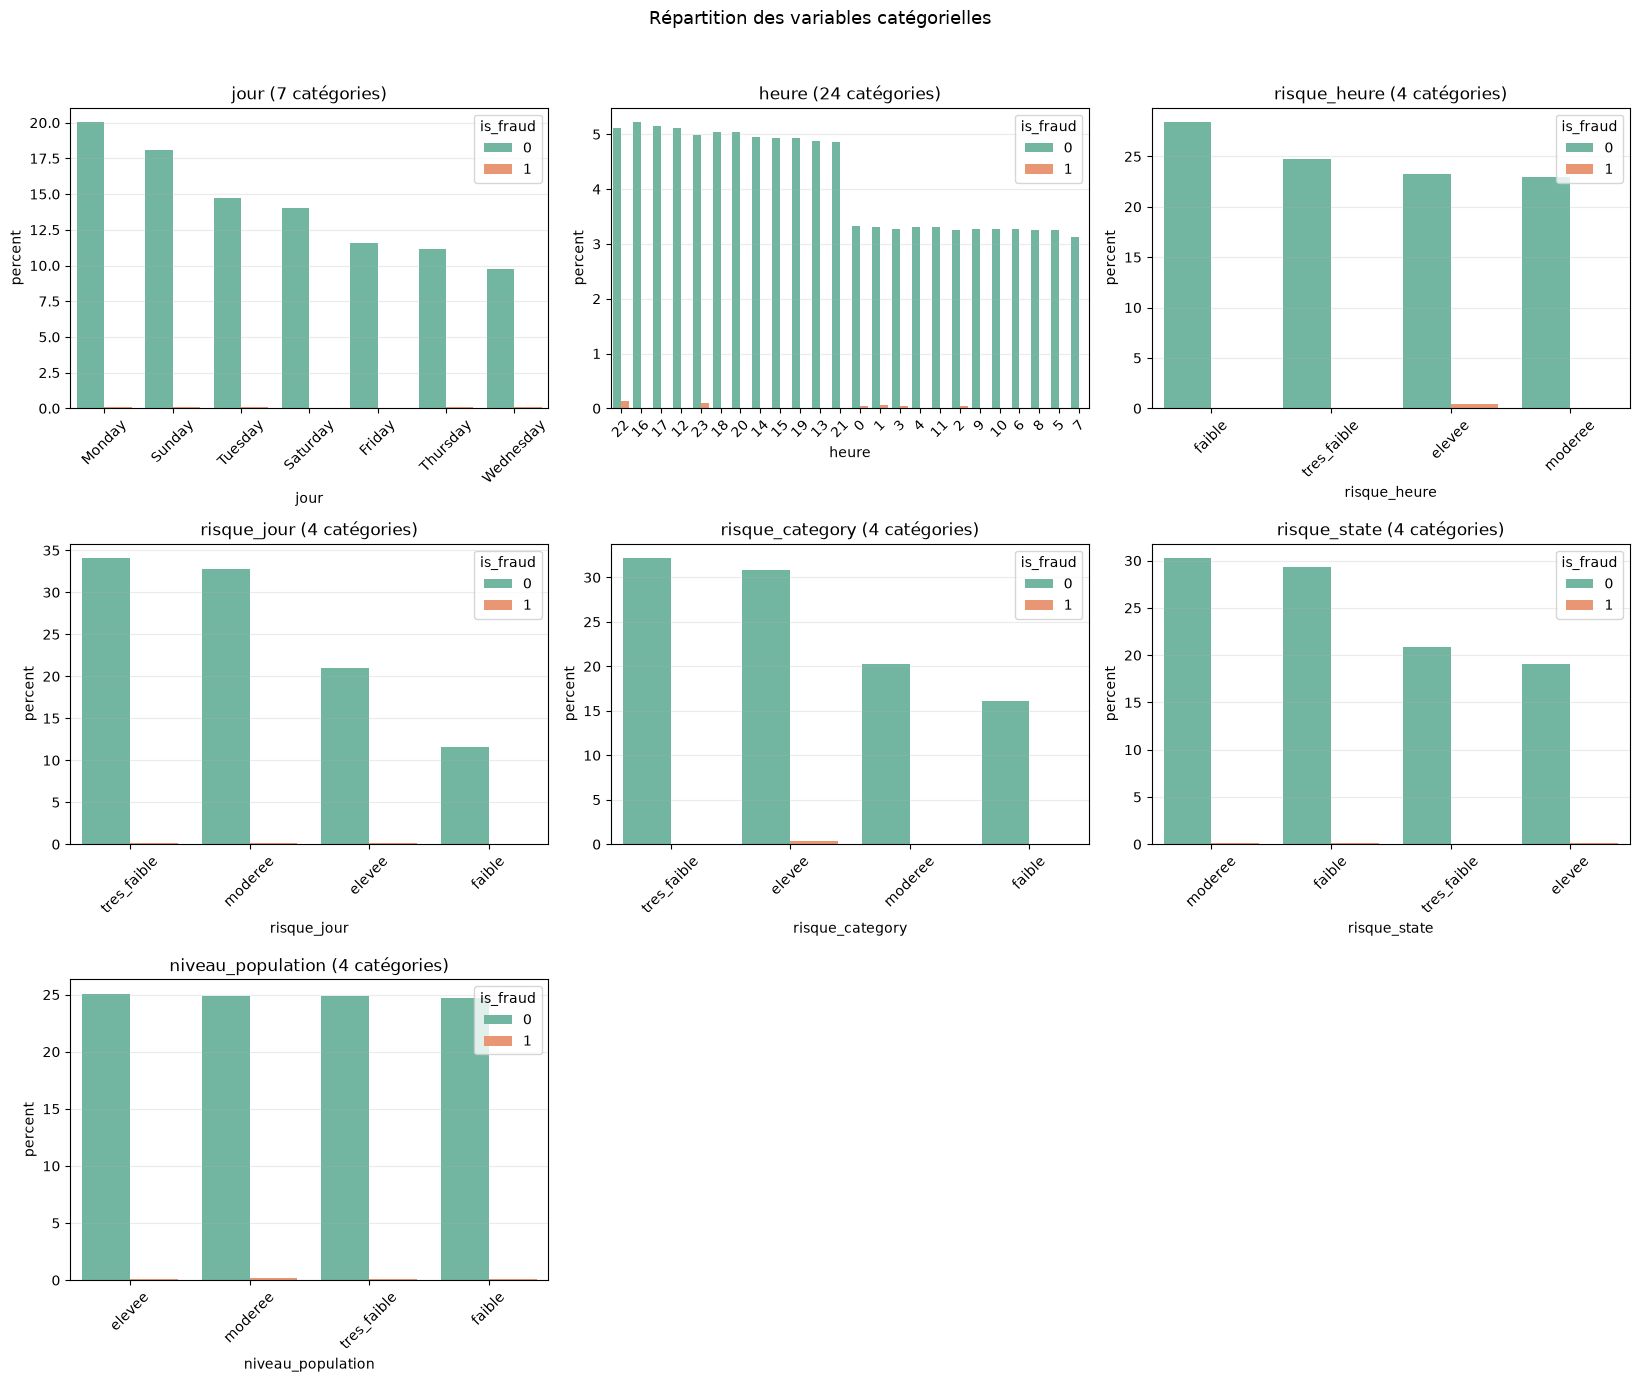

In [122]:
plot_countplots(df=df_copy,
                colonnes=["jour","heure","risque_heure","risque_jour","risque_category","risque_state","niveau_population"],
                hue="is_fraud",
                order_by_freq=True,
                stat="percent")

In [127]:
# df_copy.query("is_fraud==1").filter(["risque_heure"]).value_counts()
# df_copy.query("is_fraud==1").filter(["risque_jour"]).value_counts()
# df_copy.query("is_fraud==1").filter(["risque_category"]).value_counts()
# df_copy.query("is_fraud==1").filter(["risque_state"]).value_counts()
# df_copy.query("is_fraud==1").filter(["niveau_population"]).value_counts()
df_copy.query("is_fraud==1").filter(["niveau_age"]).value_counts()

niveau_age 
elevee         83
moderee        67
tres_faible    56
faible         55
Name: count, dtype: int64

In [121]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 50001 entries, 0 to 50000
Data columns (total 39 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   id                            50001 non-null  uint32        
 1   trans_date_trans_time         50001 non-null  datetime64[us]
 2   merchant                      50001 non-null  category      
 3   category                      50001 non-null  category      
 4   amt                           50001 non-null  float32       
 5   city                          50001 non-null  category      
 6   state                         50001 non-null  category      
 7   lat                           50001 non-null  float32       
 8   long                          50001 non-null  float32       
 9   city_pop                      50001 non-null  uint32        
 10  job                           50001 non-null  category      
 11  dob                           50001 non

# Tests

In [181]:
df_copy = sample_data.copy()

In [183]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 50001 entries, 0 to 50000
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     50001 non-null  uint32        
 1   trans_date_trans_time  50001 non-null  datetime64[us]
 2   merchant               50001 non-null  category      
 3   category               50001 non-null  category      
 4   amt                    50001 non-null  float32       
 5   city                   50001 non-null  category      
 6   state                  50001 non-null  category      
 7   lat                    50001 non-null  float32       
 8   long                   50001 non-null  float32       
 9   city_pop               50001 non-null  uint32        
 10  job                    50001 non-null  category      
 11  dob                    50001 non-null  datetime64[us]
 12  merch_lat              50001 non-null  float32       
 13  merch_long  

In [187]:
df_copy = df_copy.filter(["id","trans_date_trans_time","state","category","amt"])

date_transaction = pd.to_datetime(df_copy["trans_date_trans_time"], errors="raise")
jours_ordonnes = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df_copy["jour"] = pd.Categorical(
    date_transaction.dt.dayofweek.map(dict(enumerate(jours_ordonnes))),
    categories=jours_ordonnes,
    ordered=True,
)

df_copy["heure"] = date_transaction.dt.hour.astype("category")

In [188]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 50001 entries, 0 to 50000
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     50001 non-null  uint32        
 1   trans_date_trans_time  50001 non-null  datetime64[us]
 2   state                  50001 non-null  category      
 3   category               50001 non-null  category      
 4   amt                    50001 non-null  float32       
 5   jour                   50001 non-null  category      
 6   heure                  50001 non-null  category      
dtypes: category(4), datetime64[us](1), float32(1), uint32(1)
memory usage: 977.9 KB
